## 1)LIBRARY AND ACCELERATOR CHOICE

---

We will use:
  * the `torch.nn` module, which provides the layers (tensor operations packaged with their weights) and the loss function;
  * the class `DataLoader` to separate the dataset into batches.
  * the library `torchvision` because there are a lot of tools that will help to develop a picture-recognition AI.

After the choice of the accelerator used, we print it to be sure we are not using the CPU, which would slow down the training.

*Note: This notebook was run on Google Colab with a T4 GPU.*


In [ ]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(device)

cuda


## 2)DATA

---

We use the MNIST dataset that is already segmented in two parts, the data for training(60 000 pictures) and the data for testing(10 000 pictures).

Then we adapt the data with the object `transform` so we have pictures as tensors and to ensure the tensors are normalized (`Normalize`). After that we separate in batches, to be more efficient in time and have a more stable evolution of the weights.

At the end we verify that the data have the right shape: batches of 64 pictures of 28×28 pixels in shades of gray along with the digit in the picture for each of the 64 pictures.


*Note: 0.1307 is the mean of the MNIST training set and 0.3081 is its standard deviation.*


In [ ]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_data = datasets.MNIST(root="data", train=True,  download=True, transform=transform)
test_data  = datasets.MNIST(root="data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
test_loader  = DataLoader(test_data,  batch_size=64)

x, y = next(iter(train_loader))
print(x.shape, y.shape)

100%|██████████| 9.91M/9.91M [00:00<00:00, 20.3MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 498kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.65MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.67MB/s]

torch.Size([64, 1, 28, 28]) torch.Size([64])


## 3)MODEL

---

We will use the classical model with a first layer (`conv1`) that will allow the model to detect 32 patterns which would be recognised as the most important during the training on a 3 by 3 pixel zone for each pixel on the picture. We apply `ReLU` operation to introduce non-linearity in the model after every layer (except the last) and `pool` to reduce the number of pixel considered with every step by picking the best score for each square of 2 by 2 pixels.
After that a second layer (`conv2`) will be used similarly to the first layer, except that we double the number of patterns recognisable. The majority of the computation is done during this phase.

The last two layers take the whole picture into account. The first `fc1` is used after flattening the pictures in one line and evaluates 128 patterns. The second `fc2` is here because we introduce a `ReLU` in between these two layers to combine non-linearly the result of the previous layer. The output is the score for each digit.

The last two lines are here to verify that the output has the right shape: a tensor grouping the 10 scores for each of the 64 pictures.

In [ ]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, 3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.pool  = nn.MaxPool2d(2)
        self.relu  = nn.ReLU()
        self.fc1   = nn.Linear(64 * 7 * 7, 128)
        self.fc2   = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))   # 1×28×28  → 32×14×14
        x = self.pool(self.relu(self.conv2(x)))   # 32×14×14 → 64×7×7
        x = torch.flatten(x, 1)                   # → 3136
        x = self.relu(self.fc1(x))                # → 128
        return self.fc2(x)                        # → 10 scores

model = CNN().to(device)
print(model(x.to(device)).shape)

torch.Size([64, 10])


## 4)TRAINING

---

We have two functions, one to train the model with the whole training dataset (one epoch) and one to test it with the test dataset.

For the training, we use an improved version of the Gradient Descent, `Adam`. The `loss_fn` object turn the scores into probabilities and uses them to evaluate the gap with the expected digit by using -log() on the probability of the right digit and returning the mean of the batch.

During the training, for each batch, we calculate the loss, then we reset the grad part of the model so we can after that add the new grad found using the `loss` object, and update the weights with the `optimizer` object.

For the test, we disable the grad and we do a mean of the number of times the model was right.

In [ ]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

def train_one_epoch():
    model.train()
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        loss = loss_fn(model(x), y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

def test():
    model.eval()
    correct = 0
    with torch.no_grad():
        for x, y in test_loader:
            x, y = x.to(device), y.to(device)
            correct += (model(x).argmax(1) == y).sum().item()
    return 100 * correct / len(test_data)

## 5)RESULTS

---
The first part trains the model for 3 epochs and the second one is more visual, it shows the prediction on a random picture of the test set.

After running it on a T4 GPU, the results are a training time of 51s for the 3 epochs and an accuracy of 98.74% for the first epoch, 99.07% for the second, 99.08% for the last.

We can see that between the second and third epochs, the accuracy increased by only 0.01%, thus justifying to not train for a fourth epoch.

*Note: the dataset represents digits from an american point of view, for example I have encounter a picture that look more like a cursive "a" than the two it was labelled with.*

In [ ]:
for epoch in range(3):
    train_one_epoch()
    print(f"Epoch {epoch + 1} : accuracy {test():.2f} %")

Epoch 1 : accuracy 98.74 %
Epoch 2 : accuracy 99.07 %
Epoch 3 : accuracy 99.08 %


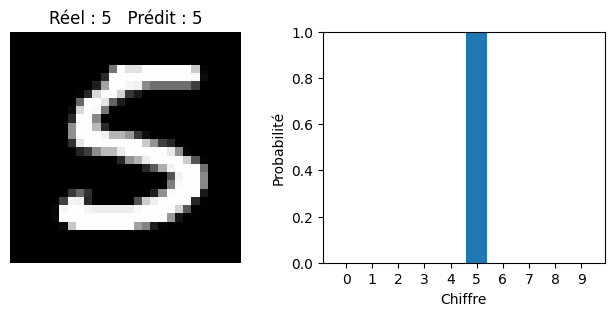

In [ ]:
import random
import matplotlib.pyplot as plt

model.eval()

idx = random.randrange(len(test_data))
image, label = test_data[idx]

with torch.no_grad():
    scores = model(image.unsqueeze(0).to(device))
    probs  = torch.softmax(scores, dim=1)[0]
    pred   = probs.argmax().item()

fig, (ax_img, ax_bar) = plt.subplots(1, 2, figsize=(8, 3))

ax_img.imshow(image.squeeze(), cmap="gray")
ax_img.set_title(f"True : {label}   Predicted : {pred}")
ax_img.axis("off")

ax_bar.bar(range(10), probs.cpu())
ax_bar.set_xticks(range(10))
ax_bar.set_xlabel("Digit")
ax_bar.set_ylabel("Probability")
ax_bar.set_ylim(0, 1)

plt.show()

## 6)SAVING THE WEIGHT

---

We save the weight for later usage.

In [ ]:
torch.save(model.state_dict(), "mnist_fp32.pt")

In [ ]:
from google.colab import files
files.download("mnist_fp32.pt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>